# Lab: Statistics Basics

Statistics is the foundation underneath almost everything in data science and machine learning — from summarizing a dataset, to understanding relationships between variables, to deciding whether a result is meaningful or just noise. This lab covers the core statistical concepts and tools you'll use throughout this program, all using tools you already have (NumPy, Pandas, SciPy) — no new software required.

**After this lab you will be able to:**
- Calculate and interpret descriptive statistics (mean, median, mode, variance, standard deviation)
- Understand and visualize the normal distribution
- Measure and interpret correlation between variables
- Understand the basics of hypothesis testing and run a simple t-test
- Know the difference between correlation and causation

**Instructions:**
- Write your code between the `### YOUR CODE HERE ###` and `### END ###` markers.
- Run each cell with **Shift + Enter**.

## Setup

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

## Descriptive Statistics

Descriptive statistics summarize a dataset with a few key numbers:

- **Mean**: the average value.
- **Median**: the middle value when data is sorted — less affected by outliers than the mean.
- **Mode**: the most frequently occurring value.
- **Variance**: the average squared distance of each point from the mean — measures spread.
- **Standard deviation**: the square root of variance — spread in the same units as the original data.

Let's calculate these on a sample dataset of exam scores.

In [25]:
scores = np.array([65, 72, 78, 81, 85, 88, 90, 92, 55, 95, 60, 100, 45, 89, 76])

print(f"Mean: {np.mean(scores):.2f}")
print(f"Median: {np.median(scores):.2f}")

values, counts = np.unique(scores, return_counts=True)
if counts.max() == 1:
    print("Mode: No unique mode - every score appears once")
else:
    print("Mode:", values[counts == counts.max()])

print(f"Variance: {np.var(scores):.2f}")
print(f"Standard deviation: {np.std(scores):.2f}")


Mean: 78.07
Median: 81.00
Mode: No unique mode - every score appears once
Variance: 236.20
Standard deviation: 15.37


**Notice:** if the mean and median are very different, that's often a sign the data is skewed (has some very high or very low values pulling the mean away from the middle).

## Practice: Comparing Mean vs. Median

**Exercise:** Given the salary data below (which includes one very high outlier salary), calculate the mean and median. Then explain in a comment which measure better represents the "typical" salary in this dataset, and why.

In [26]:
salaries = np.array([45000, 48000, 52000, 50000, 47000, 51000, 250000])

print(f"Mean: {np.mean(salaries):.2f}")
print(f"Median: {np.median(salaries):.2f}")



Mean: 77571.43
Median: 50000.00


## Percentiles and Spread

Percentiles tell you the value below which a given percentage of the data falls. The 25th percentile (Q1), 50th percentile (median), and 75th percentile (Q3) divide data into quarters, and the interquartile range (IQR = Q3 - Q1) measures the spread of the middle 50% of the data — this is the same IQR you used for outlier detection in the Data Cleaning lab.

In [27]:
q1 = np.percentile(scores, 25)
q3 = np.percentile(scores, 75)
iqr = q3 - q1

print(f"Q1 (25th percentile): {q1}")
print(f"Q3 (75th percentile): {q3}")
print(f"IQR: {iqr}")

Q1 (25th percentile): 68.5
Q3 (75th percentile): 89.5
IQR: 21.0


## The Normal Distribution

Many real-world variables (heights, test scores, measurement errors) roughly follow a normal distribution: a symmetric, bell-shaped curve where most values cluster around the mean, and values become rarer the further they are from it. Many statistical methods (including the hypothesis test later in this lab) assume data is approximately normally distributed.

Let's generate a normal distribution and visualize it.

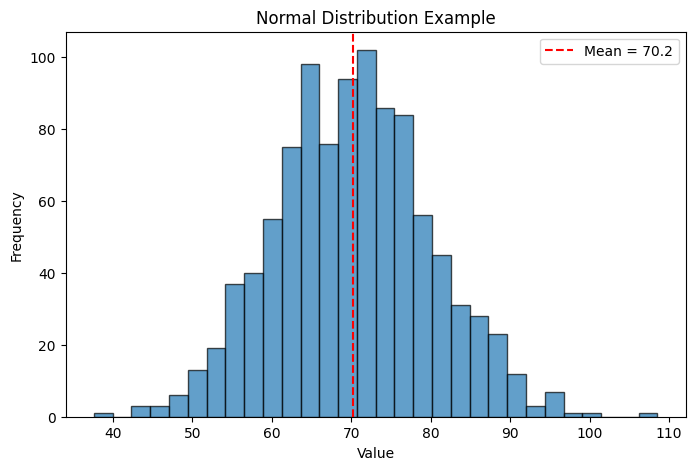

In [28]:
np.random.seed(42)
normal_data = np.random.normal(loc=70, scale=10, size=1000)  # mean=70, std=10

plt.figure(figsize=(8, 5))
plt.hist(normal_data, bins=30, edgecolor='black', alpha=0.7)
plt.axvline(np.mean(normal_data), color='red', linestyle='--', label=f'Mean = {np.mean(normal_data):.1f}')
plt.title("Normal Distribution Example")
plt.xlabel("Value")
plt.ylabel("Frequency")
plt.legend()
plt.show()

**The 68-95-99.7 rule**: in a normal distribution, about 68% of values fall within 1 standard deviation of the mean, 95% within 2 standard deviations, and 99.7% within 3 standard deviations. This is why values far from the mean (multiple standard deviations away) are considered unusual or outliers.

The histogram here shows 1,000 simulated observations with a bell distribution centred around 70; these values are concentrated near the centre and have fewer observations towards either extreme. And the dashed red line going down the middle represents the sample mean.

## Correlation

Correlation measures how strongly two numeric variables move together, on a scale from -1 to +1:

- **+1**: perfect positive correlation (as one increases, the other increases proportionally)
- **0**: no linear relationship
- **-1**: perfect negative correlation (as one increases, the other decreases proportionally)

Let's check the correlation between hours studied and exam scores in a small sample dataset.

Correlation coefficient: 0.998


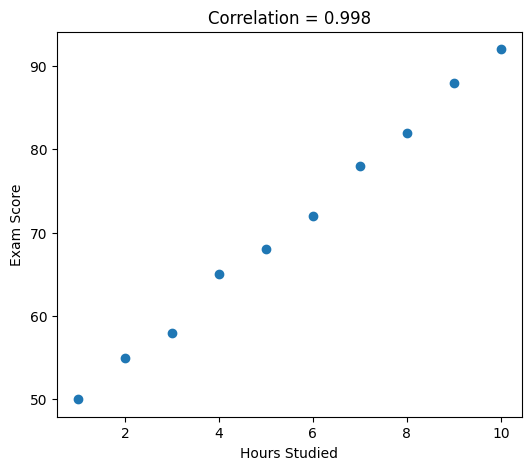

In [29]:
hours_studied = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10])
exam_score = np.array([50, 55, 58, 65, 68, 72, 78, 82, 88, 92])

correlation = np.corrcoef(hours_studied, exam_score)[0, 1]
print(f"Correlation coefficient: {correlation:.3f}")

plt.figure(figsize=(6, 5))
plt.scatter(hours_studied, exam_score)
plt.xlabel("Hours Studied")
plt.ylabel("Exam Score")
plt.title(f"Correlation = {correlation:.3f}")
plt.show()

**Important: correlation is not causation.** Two variables can be strongly correlated without one causing the other — both could be driven by a third factor, or the relationship could be coincidental. For example, ice cream sales and drowning incidents are correlated (both rise in summer), but ice cream doesn't cause drowning — hot weather drives both.

## Practice: Correlation Analysis

**Exercise:** Given the two variables below (advertising spend and sales), calculate the correlation coefficient, create a scatter plot, and write one sentence interpreting the strength and direction of the relationship.

Correlation coefficient: 0.998


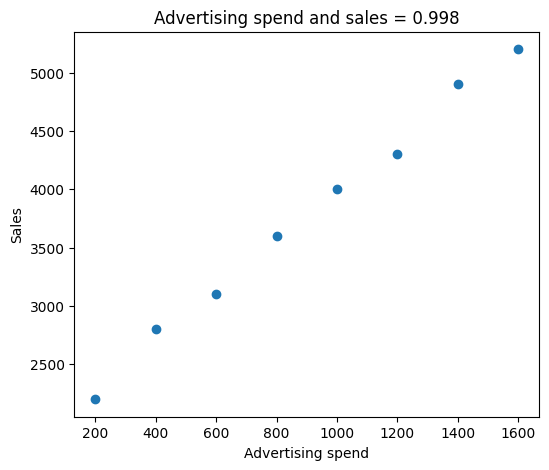

In [30]:
ad_spend = np.array([200, 400, 600, 800, 1000, 1200, 1400, 1600])
sales = np.array([2200, 2800, 3100, 3600, 4000, 4300, 4900, 5200])

correlation = np.corrcoef(ad_spend, sales)[0, 1]
print(f"Correlation coefficient: {correlation:.3f}")

plt.figure(figsize=(6, 5))
plt.scatter(ad_spend, sales)
plt.xlabel("Advertising spend")
plt.ylabel("Sales")
plt.title(f"Advertising spend and sales = {correlation:.3f}")
plt.show()

This correlation analysis shows us that advertising spend and sales move in a very positive linear relationship; however, this doesn't indicate that advertising alone caused the higher sales. Other factors, such as seasonal demand, could have influenced both the spending and the sales.

## Hypothesis Testing

Hypothesis testing is how we decide, using data, whether an observed difference or effect is likely real or could just be due to random chance. The process:

1. **Null hypothesis (H0)**: assumes there is no real effect or difference (the "boring" default assumption).
2. **Alternative hypothesis (H1)**: what you're actually trying to find evidence for (there IS a difference).
3. **p-value**: the probability of seeing a result this extreme if the null hypothesis were actually true. A small p-value (conventionally < 0.05) suggests the observed difference is unlikely to be due to chance alone, so we reject the null hypothesis.

Let's test whether two groups of students (who used different study methods) have significantly different average scores, using an independent t-test.

In [31]:
method_a_scores = np.array([72, 75, 78, 74, 77, 73, 76, 79])
method_b_scores = np.array([80, 83, 85, 81, 84, 82, 86, 87])

t_statistic, p_value = stats.ttest_ind(method_a_scores, method_b_scores)

print(f"Method A mean: {np.mean(method_a_scores):.2f}")
print(f"Method B mean: {np.mean(method_b_scores):.2f}")
print(f"T-statistic: {t_statistic:.3f}")
print(f"P-value: {p_value:.5f}")

alpha = 0.05
if p_value < alpha:
    print("\nResult: statistically significant difference (reject H0)")
else:
    print("\nResult: no statistically significant difference (fail to reject H0)")

Method A mean: 75.50
Method B mean: 83.50
T-statistic: -6.532
P-value: 0.00001

Result: statistically significant difference (reject H0)


**Interpreting this result:** if the p-value is below our significance level (commonly 0.05), we conclude the difference between the two study methods is unlikely to be due to random chance — there's likely a real effect. If the p-value is above 0.05, we don't have strong enough evidence to say the methods differ.

## Practice: Running Your Own Hypothesis Test

**Exercise:** Two versions of a website (A and B) were shown to different users, and their time-on-page (in seconds) was recorded below. Run a t-test to determine if there's a statistically significant difference between the two versions. State your conclusion clearly (significant or not, at the 0.05 level).

In [32]:
version_a_time = np.array([45, 52, 48, 50, 47, 44, 49, 51, 46])
version_b_time = np.array([58, 62, 55, 60, 57, 61, 59, 56, 63])

t_statistic, p_value = stats.ttest_ind(version_a_time, version_b_time)

print(f"Version A mean: {np.mean(version_a_time):.2f} seconds")
print(f"Version B mean: {np.mean(version_b_time):.2f} seconds")
print(f"T-statistic: {t_statistic:.3f}")
print(f"P-value: {p_value:.5f}")

alpha = 0.05
if p_value < alpha:
    print("\nResult: statistically significant difference (reject H0)")
else:
    print("\nResult: no statistically significant difference (fail to reject H0)")

Version A mean: 48.00 seconds
Version B mean: 59.00 seconds
T-statistic: -8.521
P-value: 0.00000

Result: statistically significant difference (reject H0)


At the 0.05 significance level, we reject the null hypothesis of equal population means and conclude that version B is 11 seconds longer than version A. This doesn't mean B is better; a longer time could indicate either engagement or difficulty using the website.

**What to remember from this lab:**
- Mean can be misleading with outliers — median is often more robust
- Standard deviation and IQR both measure spread, useful for understanding variability and detecting outliers
- The normal distribution and the 68-95-99.7 rule underlie many statistical methods
- Correlation measures relationship strength/direction, but never proves causation
- Hypothesis testing (like a t-test) uses p-values to judge whether a difference is likely real or due to chance

## Lab Tasks

Complete the following tasks in this notebook, below this cell.

1. **Descriptive Summary**: Choose or generate a numeric dataset of at least 15 values (your choice of topic). Calculate and report the mean, median, mode, variance, standard deviation, and IQR. Note whether the data appears skewed based on the mean vs. median comparison.
2. **Distribution Visualization**: Generate 500 random values from a normal distribution with a mean and standard deviation of your choice. Plot a histogram and mark the mean with a vertical line.
3. **Correlation Study**: Create or find two related numeric variables (e.g., temperature and ice cream sales, age and reaction time). Calculate their correlation coefficient, create a scatter plot, and write 2-3 sentences interpreting the result — including whether you think there could be a causal relationship or not, and why.
4. **Hypothesis Test**: Design your own two-group comparison scenario (e.g., two teaching methods, two product versions, two marketing campaigns). Create sample data for both groups, run a t-test, and state your conclusion at the 0.05 significance level.
5. **Reflection**: In a markdown cell, explain in your own words why understanding statistics matters before building machine learning models, using at least one specific example from this lab.

In [33]:
import numpy as np
from scipy import stats

# Task 1
# Choosing a dataset of 15 values (e.g., daily high temperatures in Fahrenheit)
random_numbers = np.array([30, 34, 28, 28, 39, 38, 85, 944, 73, 92, 64, 20, 35, 42, 31])

q1 = np.percentile(random_numbers, 25)
q3 = np.percentile(random_numbers, 75)
iqr = q3 - q1

print(f"Mean: {np.mean(random_numbers):.2f}")
print(f"Median: {np.median(random_numbers):.2f}")
print("Mode:", stats.mode(random_numbers, keepdims=True).mode[0])
print(f"Variance: {np.var(random_numbers):.2f}")
print(f"Standard deviation: {np.std(random_numbers):.2f}")
print(f"Q1: {q1:.2f}")
print(f"Q3: {q3:.2f}")
print(f"IQR: {iqr:.2f}")

# Note on skewness:
# The mean (approx. 105.20) is significantly higher than the median (35.00).
# This large difference indicates that the data is highly right-skewed due to the extreme outlier (944).

Mean: 105.53
Median: 38.00
Mode: 28
Variance: 50675.32
Standard deviation: 225.11
Q1: 30.50
Q3: 68.50
IQR: 38.00


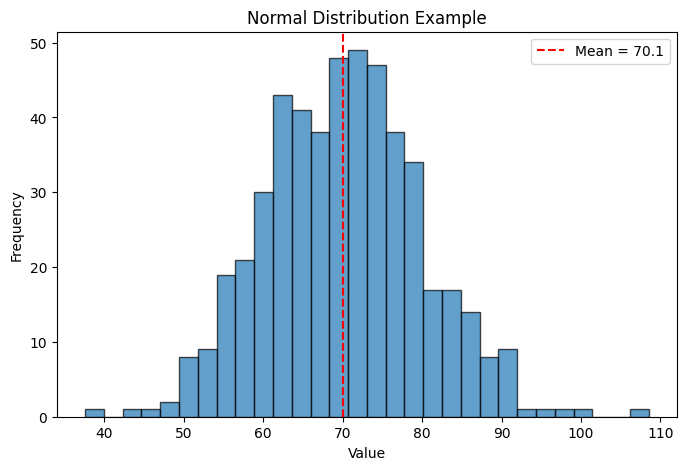

In [34]:
# Task 2
np.random.seed(42)

normal_data = np.random.normal(loc=70, scale=10, size=500)

plt.figure(figsize=(8, 5))
plt.hist(normal_data, bins=30, edgecolor='black', alpha=0.7)

plt.axvline(
    np.mean(normal_data),
    color='red',
    linestyle='--',
    label=f'Mean = {np.mean(normal_data):.1f}'
)

plt.title("Normal Distribution Example")
plt.xlabel("Value")
plt.ylabel("Frequency")
plt.legend()
plt.show()

Correlation coefficient: 0.998


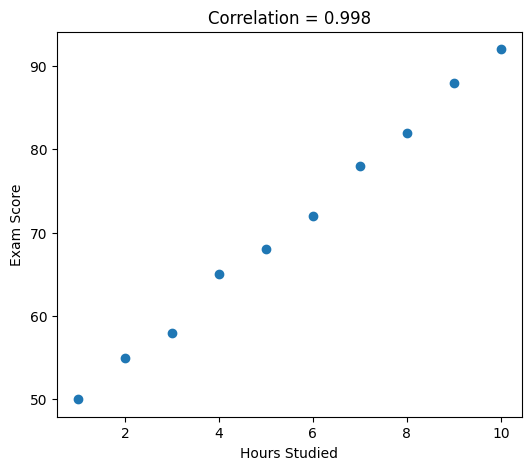

In [35]:
# Task 3
hours_studied = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10])
exam_score = np.array([50, 55, 58, 65, 68, 72, 78, 82, 88, 92])

correlation = np.corrcoef(hours_studied, exam_score)[0, 1]
print(f"Correlation coefficient: {correlation:.3f}")

plt.figure(figsize=(6, 5))
plt.scatter(hours_studied, exam_score)
plt.xlabel("Hours Studied")
plt.ylabel("Exam Score")
plt.title(f"Correlation = {correlation:.3f}")
plt.show()

The correlation coefficient of approximately 0.998 shows a very strong positive linear relationship between hours studied and exam scores in this example. Studying more could plausibly improve scores, but the correlation alone does not prove causation. Other factors, such as motivation or prior knowledge, could influence both study time and exam performance.

In [36]:
# Task 4
version_a_time = np.array([45, 52, 48, 50, 47, 44, 49, 51, 46])
version_b_time = np.array([58, 62, 55, 60, 57, 61, 59, 56, 63])

t_statistic, p_value = stats.ttest_ind(
    version_a_time, version_b_time
)

print(f"Version A mean: {np.mean(version_a_time):.2f}")
print(f"Version B mean: {np.mean(version_b_time):.2f}")
print(f"T-statistic: {t_statistic:.3f}")
print(f"P-value: {p_value:.5f}")

alpha = 0.05

if p_value < alpha:
    print("Statistically significant difference: reject H0.")
else:
    print("No statistically significant difference: fail to reject H0.")

Version A mean: 48.00
Version B mean: 59.00
T-statistic: -8.521
P-value: 0.00000
Statistically significant difference: reject H0.


At the 0.05 significance level, we reject the null hypothesis of equal population mean times. Version B’s sample mean is 11 seconds higher than Version A’s. Under the test’s assumptions, this provides evidence of a difference in mean time-on-page, although longer time alone does not establish a better user experience.

Understanding statistics helps me understand a dataset before building a machine learning model. For example, in the salary exercise, the unusually high salary pulled the mean upwards, while the median better represented a typical salary. Standard deviation and IQR help describe how spread out the values are. Correlation helps identify relationships between variables, but it does not prove causation. Hypothesis testing helps assess evidence for differences between groups, although statistical significance still needs practical interpretation.